In [43]:
import pandas as pd
import warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.optimize import curve_fit
import matplotlib.colors as mcolors
from matplotlib.colors import to_hex
from IPython.display import HTML, display
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl') #Remove annoying warning

# Plotting NMR relaxation data and sPRE
Takes data from DynamicsCenter, T1 and T2 relaxation experiments, 15N HSQC. BaCBM2 and ScCBM2. Writes scripts for coloring in pymol (folders: pymol_relax, pymol_changes).

In [44]:
def createT1T2_df(path, CBM, HN=False, NobsT1=False):
    df = pd.read_excel(path, "Results")
    #Create AA colunm
    if HN == True:
        df = df[~df["Peak name"].str.contains("HE1/NE1", na=False)] #remove sidechain data
        df[['Type', 'AA']] = df['Peak name'].str.split(' ', n=1, expand=True) #Split out the amino acid from the proton type.
    else: 
        df['AA'] = df['Peak name']

    df['AA_no'] = df['AA'].str[1:]   #Put the amino acid number in column AA_no.
    df['AA_no'] = df['AA_no'].astype(int)

    #correct sequence numbers:
    if CBM == 'Ba':
        df['AA_no'] = df['AA_no']-7
    elif CBM == 'Sc':
        df['AA_no'] = df['AA_no']-2
        

    #create new df:
    df2 = pd.DataFrame(df[['AA', 'AA_no']])
    if NobsT1 == True:
        df2[['T','T_err', 'R', 'R_err']] = df.iloc[:,[5,6,10,11]]   #15N-observed T1 experiments have more columns in DC-output file
    else:
        df2[['T','T_err', 'R', 'R_err']] = df.iloc[:,[5,6,8,9]]
    
    return df2

    

In [45]:
def get_colors(df, colormap, y_name):
    y = df[y_name]
    x = df['AA_no']
    
    avg = y.mean()
    std = y.std()

    #color map
    cmap = plt.get_cmap(colormap)
    #define y range for color map
    norm = mcolors.Normalize(vmin=y.min(), vmax=y.max())
    if y_name == 'a': #(PRE)
        norm = mcolors.Normalize(vmin=0, vmax=avg+std)
            
    colors = cmap(norm(y))

    return cmap, norm, colors, avg, std


def plot_R(dfs, list_of_legends, ylim, R1R2, ax, list_of_colors=None, colormaps=None):
        
    plt.rcParams.update({
        "font.size": 8,        # base font size
        "axes.labelsize": 10,   # axis labels
        "xtick.labelsize": 8,  # x tick labels
        "ytick.labelsize": 8,  # y tick labels
        "legend.fontsize": 8,  # legend
    })
    
    width_mm = 130
    width_in = width_mm / 25.4 
    height_in = width_in * 0.5

    #define colors
    if list_of_colors is not None:    
        ax.set_prop_cycle(color=list_of_colors)
        for i in range(len(dfs)):
            ax.errorbar(dfs[i]['AA_no'], dfs[i]['R'], yerr = dfs[i]['R_err'], fmt='.', elinewidth=0.8, capsize=1.5, capthick=0.8, alpha = 0.7, label = list_of_legends[i])

    elif colormaps is not None:
        print("Using colormap branch")
        for i in range(len(dfs)):
            cmap, norm, colors, avg, std = get_colors(dfs[i], colormaps[i], 'R')
            x = dfs[i]['AA_no']
            y = dfs[i]['R']
            yerr = dfs[i]['R_err']

            ax.axhline(avg+std, color = cmap(norm(avg+std)), linewidth = 0.8, linestyle = '--', zorder=0)
            ax.axhline(avg, color = cmap(norm(avg)), linewidth = 0.8, zorder=0)
            ax.errorbar(x, y, yerr = yerr, fmt='none', ecolor='gray', elinewidth=0.8, capsize=1.5, capthick=0.8, zorder=1)
            ax.scatter(x, y, c=colors, s=15, label = list_of_legends[i], zorder=2)
            
    else:
        for i in range(len(dfs)):
            ax.errorbar(dfs[i]['AA_no'], dfs[i]['R'], yerr = dfs[i]['R_err'], fmt='.', elinewidth=0.8, capsize=1.5, capthick=0.8, alpha = 0.7, label = list_of_legends[i])
    
    if R1R2 == 'R1':
        ax.set_ylabel('R1 (s$^{-1}$)')
        ax.yaxis.set_major_locator(ticker.MultipleLocator(0.5))
    elif R1R2 == 'R2':
        ax.set_ylabel('R2 (s$^{-1}$)')
        ax.yaxis.set_major_locator(ticker.MultipleLocator(5))
        
    ax.set_xlabel('Residue number')
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.set_ylim(ylim)

def plot_R_lines(dfs, list_of_legends, ylim, R1R2, ax, list_of_colors=None):
        
    plt.rcParams.update({
        "font.size": 8,        # base font size
        "axes.labelsize": 10,   # axis labels
        "xtick.labelsize": 8,  # x tick labels
        "ytick.labelsize": 8,  # y tick labels
        "legend.fontsize": 8,  # legend
    })
    
    width_mm = 130
    width_in = width_mm / 25.4 
    height_in = width_in * 0.5

    #define colors
    if list_of_colors is not None:    
        ax.set_prop_cycle(color=list_of_colors) 
        
    for i in range(len(dfs)):
        ax.plot(dfs[i]['AA_no'], dfs[i]['R'], alpha = 1, linewidth = 0.5, label = list_of_legends[i])
    
    if R1R2 == 'R1':
        ax.set_ylabel('R1 (s$^{-1}$)')
        ax.yaxis.set_major_locator(ticker.MultipleLocator(0.5))
    elif R1R2 == 'R2':
        ax.set_ylabel('R2 (s$^{-1}$)')
        ax.yaxis.set_major_locator(ticker.MultipleLocator(5))
        
    ax.set_xlabel('Residue number')
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.set_ylim(ylim)

def pymol_colors(df, colormap, y_name, label):
    cmap, norm, colors, avg, std = get_colors(df, colormap, y_name)
    y = df[y_name]
    x = df['AA_no']
    
    avg = y.mean()
    res_above_avg = x[y > avg].tolist()
    std = y.std()
    res_above_avg_std = x[y > (avg + std)].tolist()

    #Pymol show sticks:
    print(f"\n------------{label}------------------")
    print(f"Average CSP: {avg:.4f}")
    print(f"Std Dev:     {std:.4f}")
    
    print("\nResidues above average:")
    print(res_above_avg)
    print("Residues above average + std:")
    print(res_above_avg_std)
    
    # PyMOL selections
    print("\nPyMOL commands:")
    print("select high_" + label + ", " + label + " and resi " + "+".join(map(str, res_above_avg)))
    print("select high_std_" + label + ", " + label + " and resi " + "+".join(map(str, res_above_avg_std)) + "\n")

    #pymol coloring
    rgb_colors = {}
    for resi, value in zip(x, y):
        if pd.isna(value):
            continue
        r, g, b, _ = cmap(norm(value))
        rgb_colors[int(resi)] = (r, g, b)

    
    filename = f"pymol_relax/pymol_colors_{label}.pml"
    with open(filename, "w") as f:
        if 'Sc' in label:
            f.write(f"set_name fold_sccbm2_model_0, {label}\n")
        elif 'Ba' in label: 
            f.write(f"set_name fold_bacbm2_model_0, {label}\n")

        f.write(f"color white, {label}\n")
        for resi, (r, g, b) in rgb_colors.items():
            color_name = f"c_{resi}_{label}"
    
            f.write(
                f"set_color {color_name}, [{r:.4f}, {g:.4f}, {b:.4f}]\n"
            )
            f.write(
                f"color {color_name}, {label} and resi {resi}\n"
            )

        f.write(f"select high_{label}, {label} and resi {'+'.join(map(str, res_above_avg))}\n")
        f.write(f"select high_std_{label}, {label} and resi {'+'.join(map(str, res_above_avg_std))}\n")



def show_colored_sequence(sequence, df, colormap, y_name):
    """
    Display the protein sequence with residue-specific colors based on df['color'].
    - sequence: str, full protein sequence
    - df: DataFrame with columns ['nmrResidueCode', 'color']
    """

    cmap, norm, colors, avg, std = get_colors(df, colormap, y_name)
    colors = [to_hex(c) for c in colors]
    
    
    html_seq = ""
    for i, aa in enumerate(sequence, start=1):
        # find color for this residue (default grey if missing)
        matches = df.index[df['AA_no'] == i]

        if len(matches):
            pos = df.index.get_loc(matches[0])
            color = colors[pos]
        else:
            color = "#B5B3B3"
        html_seq += f"<span style='color:{color}; font-family:monospace;'>{aa}</span>"
    

    display(HTML(html_seq))



## 15N observed relaxation rates

In [46]:
#15N observed data:
df_15N_T1_Ba = createT1T2_df('DynamicsCenter_data/15N/15N-T1-BaCBM2.xlsx', 'Ba', NobsT1=True)
df_15N_T1_Sc = createT1T2_df('DynamicsCenter_data/15N/15N-T1-ScCBM2.xlsx', CBM = 'Sc', HN=True, NobsT1=True)

sequence_Sc = 'GSCMAVYSVENSWSGGFQGSVEVMNHGTEPLNGWAVQWQPGGGTTLGGVWNGSLTSGSDGTVTVRNVDHNRVVPPDGSVTFGFTATSTGNDFPVDSIGCVAP'
sequence_Ba = 'ATFSVTSNWGSGYNFSIVIKNSGTTPIKNWKLEFDYNGNLTQVWDSKISSKINNHYVITNAGWNGEIPPGGSITIGGAGTGTPAELVNASISEN'

Using colormap branch

------------15_NR1_Ba_free------------------
Average CSP: 1.4200
Std Dev:     0.0990

Residues above average:
[1, 2, 3, 4, 5, 6, 13, 14, 15, 16, 19, 20, 21, 22, 28, 30, 32, 34, 35, 41, 43, 44, 49, 50, 59, 61, 62, 64, 66, 67, 71, 73, 75, 80, 86, 87, 88, 89, 91, 92, 94]
Residues above average + std:
[16, 28, 30, 35, 43, 49, 59, 61, 66, 88]

PyMOL commands:
select high_15_NR1_Ba_free, 15_NR1_Ba_free and resi 1+2+3+4+5+6+13+14+15+16+19+20+21+22+28+30+32+34+35+41+43+44+49+50+59+61+62+64+66+67+71+73+75+80+86+87+88+89+91+92+94
select high_std_15_NR1_Ba_free, 15_NR1_Ba_free and resi 16+28+30+35+43+49+59+61+66+88



Using colormap branch

------------15N_R1_Sc_free------------------
Average CSP: 1.1175
Std Dev:     0.1384

Residues above average:
[1, 2, 11, 13, 16, 17, 21, 22, 23, 24, 26, 32, 34, 36, 38, 39, 42, 46, 50, 51, 53, 55, 56, 58, 60, 64, 66, 67, 69, 71, 76, 78, 79, 81, 82, 83, 85, 92, 95, 97, 100, 101]
Residues above average + std:
[1, 2, 13, 34, 56, 66, 69, 81, 100, 101]

PyMOL commands:
select high_15N_R1_Sc_free, 15N_R1_Sc_free and resi 1+2+11+13+16+17+21+22+23+24+26+32+34+36+38+39+42+46+50+51+53+55+56+58+60+64+66+67+69+71+76+78+79+81+82+83+85+92+95+97+100+101
select high_std_15N_R1_Sc_free, 15N_R1_Sc_free and resi 1+2+13+34+56+66+69+81+100+101



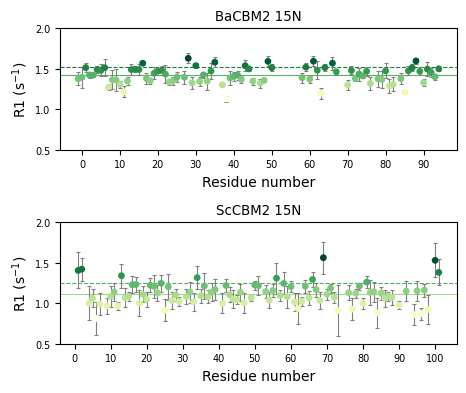

In [47]:
width_mm = 130
width_in = width_mm / 25.4 
height_in = width_in * 0.8

colormaps = ['YlGn']

fig, ax = plt.subplots(2, 1, figsize =((width_in,height_in)), sharey = True)
fig.subplots_adjust(hspace=0.6)

dfs = [df_15N_T1_Ba]
plot_R(dfs, ['Ba'], (0,2), 'R1', ax[0], colormaps = colormaps)
pymol_colors(dfs[0], colormaps[0], 'R', '15_NR1_Ba_free')
show_colored_sequence(sequence_Ba, dfs[0], colormaps[0], 'R')
ax[0].set_title('BaCBM2 15N')

dfs = [df_15N_T1_Sc]
plot_R(dfs, ['Sc'], (0,2), 'R1', ax[1], colormaps = colormaps)
pymol_colors(dfs[0], colormaps[0], 'R', '15N_R1_Sc_free')
show_colored_sequence(sequence_Sc, dfs[0], colormaps[0], 'R')
ax[0].set_ylim(0.5,2)
ax[1].set_title('ScCBM2 15N')

plt.savefig('Plots/15N-R1_BaSc.png', dpi = 600, bbox_inches = 'tight')
plt.savefig('Plots/15N-R1_BaSc.svg', bbox_inches = 'tight')

## 1H observed relaxation rates 

In [48]:
# Data 

#free ScCBM2
T1_Sc_free_0 = createT1T2_df('DynamicsCenter_data/ScCBM2_free/T1/Sc_T1_0mM.xlsx', 'Sc', HN=True)
T1_Sc_free_025 = createT1T2_df('DynamicsCenter_data/ScCBM2_free/T1/Sc_T1_025mM.xlsx', 'Sc', HN=True)
T1_Sc_free_05 = createT1T2_df('DynamicsCenter_data/ScCBM2_free/T1/Sc_T1_05mM.xlsx', 'Sc', HN=True)
T1_Sc_free_1 = createT1T2_df('DynamicsCenter_data/ScCBM2_free/T1/Sc_T1_1mM.xlsx', 'Sc', HN=True)

T2_Sc_free_0 = createT1T2_df('DynamicsCenter_data/ScCBM2_free/T2/T2_1s_0mM-removed.xlsx', 'Sc', HN=True)
T2_Sc_free_025 = createT1T2_df('DynamicsCenter_data/ScCBM2_free/T2/T2_1s_025mM-removed.xlsx', 'Sc', HN=True)
T2_Sc_free_05 = createT1T2_df('DynamicsCenter_data/ScCBM2_free/T2/T2_1s_05mM-removed.xlsx', 'Sc', HN=True)
T2_Sc_free_1 = createT1T2_df('DynamicsCenter_data/ScCBM2_free/T2/T2_1s_1mM-removed.xlsx', 'Sc', HN=True)
T2_x_Sc_free_0 = createT1T2_df('DynamicsCenter_data/ScCBM2_free/T2_2/T2_0mM.xlsx', 'Sc', HN=True)

#free BaCBM2
T1_Ba_free_0 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T1_0mM.xlsx', 'Ba')
T1_Ba_free_025 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T1_025mM.xlsx', 'Ba')
T1_Ba_free_05 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T1_05mM.xlsx', 'Ba')
T1_Ba_free_075 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T1_075mM.xlsx', 'Ba')

T2_Ba_free_0 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T2_0mM.xlsx', 'Ba')
T2_Ba_free_025 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T2_025mM.xlsx', 'Ba')
T2_Ba_free_05 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T2_05mM.xlsx', 'Ba')
T2_Ba_free_075 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T2_075mM.xlsx', 'Ba')

#BaCBM2 + BHET
T1_Ba_bhet_0 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T1_BHET_0mM.xlsx', 'Ba')
T1_Ba_bhet_025 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T1_BHET_025mM.xlsx', 'Ba')
T1_Ba_bhet_05 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T1_BHET_05mM.xlsx', 'Ba')
T1_Ba_bhet_075 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T1_BHET_075mM.xlsx', 'Ba')

T2_Ba_bhet_0 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T2_BHET_0mM.xlsx', 'Ba')
T2_Ba_bhet_025 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T2_BHET_025mM.xlsx', 'Ba')
T2_Ba_bhet_05 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T2_BHET_05mM.xlsx', 'Ba')
T2_Ba_bhet_075 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T2_BHET_075mM.xlsx', 'Ba')

#BaCBM2 + PET
T1_Ba_pet_0 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T1_PET_0mM.xlsx', 'Ba')
T1_Ba_pet_025 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T1_PET_025mM.xlsx', 'Ba')
T1_Ba_pet_05 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T1_PET_05mM.xlsx', 'Ba')
T1_Ba_pet_075 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T1_PET_075mM.xlsx', 'Ba')

T2_Ba_pet_0 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T2_PET_0mM.xlsx', 'Ba')
T2_Ba_pet_025 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T2_PET_025mM.xlsx', 'Ba')
T2_Ba_pet_05 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T2_PET_05mM.xlsx', 'Ba')
T2_Ba_pet_075 = createT1T2_df('DynamicsCenter_data/BaCBM2/Ba_T2_PET_075mM.xlsx', 'Ba')


Using colormap branch



------------R1_Sc_free------------------
Average CSP: 0.5835
Std Dev:     0.1201

Residues above average:
[2, 4, 5, 15, 22, 23, 24, 27, 28, 29, 32, 37, 41, 42, 44, 45, 46, 48, 49, 54, 55, 56, 57, 60, 61, 62, 63, 64, 65, 68, 72, 73, 80, 81, 88, 89, 90, 95, 97, 98, 99, 100, 101]
Residues above average + std:
[15, 28, 41, 63, 68, 80, 90, 98, 101]

PyMOL commands:
select high_R1_Sc_free, R1_Sc_free and resi 2+4+5+15+22+23+24+27+28+29+32+37+41+42+44+45+46+48+49+54+55+56+57+60+61+62+63+64+65+68+72+73+80+81+88+89+90+95+97+98+99+100+101
select high_std_R1_Sc_free, R1_Sc_free and resi 15+28+41+63+68+80+90+98+101

Using colormap branch



------------R2_Sc_free------------------
Average CSP: 39.7292
Std Dev:     11.2319

Residues above average:
[0, 2, 6, 7, 12, 15, 18, 19, 23, 26, 28, 31, 32, 36, 39, 41, 42, 46, 47, 50, 51, 54, 56, 60, 67, 68, 69, 82, 83, 84, 88, 89, 90, 91, 94, 96, 99, 100, 101]
Residues above average + std:
[6, 32, 41, 42, 50, 51, 54, 56, 60, 88, 91, 94, 99]

PyMOL commands:
select high_R2_Sc_free, R2_Sc_free and resi 0+2+6+7+12+15+18+19+23+26+28+31+32+36+39+41+42+46+47+50+51+54+56+60+67+68+69+82+83+84+88+89+90+91+94+96+99+100+101
select high_std_R2_Sc_free, R2_Sc_free and resi 6+32+41+42+50+51+54+56+60+88+91+94+99



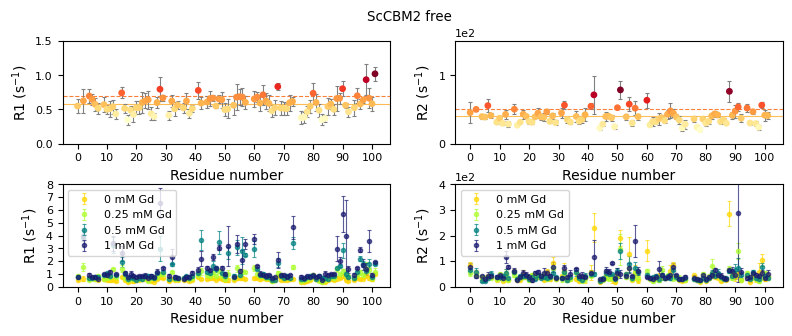

In [49]:
#ScCBM2
width_mm = 200
width_in = width_mm / 25.4 
height_in = width_in * 0.4
fig, ax = plt.subplots(2, 2, figsize =((width_in,height_in)), sharey = False)
fig.tight_layout()
fig.subplots_adjust(top=0.88)
fig.subplots_adjust(hspace=0.4)
fig.subplots_adjust(wspace=0.2)
fig.suptitle("ScCBM2 free")

# R1
dfs = [T1_Sc_free_0]
list_of_legends = ['ScCBM2 0mM Gd']
colormaps = ["YlOrRd"]
plot_R(dfs, list_of_legends, (0,1.5), 'R1', ax[0,0], colormaps = colormaps)
show_colored_sequence(sequence_Sc, dfs[0], colormaps[0], 'R')
pymol_colors(dfs[0], colormaps[0], 'R', 'R1_Sc_free')

# R1 - with Gd
dfs = [T1_Sc_free_0, T1_Sc_free_025, T1_Sc_free_05, T1_Sc_free_1]
list_of_legends = ['0 mM Gd', '0.25 mM Gd', '0.5 mM Gd', '1 mM Gd']
list_of_colors = ['gold', 'greenyellow', 'teal', 'midnightblue']
plot_R(dfs, list_of_legends, (0,8), 'R1', ax[1,0], list_of_colors)
ax[1,0].yaxis.set_major_locator(ticker.MultipleLocator(1))
ax[1,0].legend(loc = 'upper left')

# R2
dfs = [T2_x_Sc_free_0]
list_of_legends = ['ScCBM2 0mM Gd']
colormaps = ["YlOrRd"]
plot_R(dfs, list_of_legends, (0,150), 'R2', ax[0,1], colormaps = colormaps)
show_colored_sequence(sequence_Sc, dfs[0], colormaps[0], 'R')
pymol_colors(dfs[0], colormaps[0], 'R', 'R2_Sc_free')
ax[0,1].yaxis.set_major_locator(ticker.MultipleLocator(100))
ax[0,1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

# R2 - with Gd, d1=1s
dfs = [T2_Sc_free_0, T2_Sc_free_025, T2_Sc_free_05, T2_Sc_free_1]
list_of_legends = ['0 mM Gd', '0.25 mM Gd', '0.5 mM Gd', '1 mM Gd']
list_of_colors = ['gold', 'greenyellow', 'teal', 'midnightblue']
plot_R(dfs, list_of_legends, (0,400), 'R2', ax[1,1], list_of_colors)
ax[1,1].yaxis.set_major_locator(ticker.MultipleLocator(100))
ax[1,1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax[1,1].legend(loc = 'upper left')

plt.savefig('Plots/Relax_ScCBM2_free.svg', bbox_inches='tight')

Using colormap branch



------------R1_Ba_free------------------
Average CSP: 0.5288
Std Dev:     0.1175

Residues above average:
[1, 2, 3, 8, 12, 13, 18, 19, 20, 21, 22, 24, 25, 28, 33, 37, 39, 40, 41, 42, 43, 47, 48, 49, 50, 58, 59, 73, 74, 75, 80, 82, 85, 86, 88, 89, 90, 91, 92, 93, 94]
Residues above average + std:
[1, 12, 43, 48, 74, 88, 89, 91, 93]

PyMOL commands:
select high_R1_Ba_free, R1_Ba_free and resi 1+2+3+8+12+13+18+19+20+21+22+24+25+28+33+37+39+40+41+42+43+47+48+49+50+58+59+73+74+75+80+82+85+86+88+89+90+91+92+93+94
select high_std_R1_Ba_free, R1_Ba_free and resi 1+12+43+48+74+88+89+91+93

Using colormap branch



------------R2_Ba_free------------------
Average CSP: 26.5184
Std Dev:     6.9890

Residues above average:
[6, 8, 10, 14, 16, 17, 18, 19, 21, 22, 27, 28, 29, 30, 31, 33, 35, 37, 38, 39, 40, 41, 45, 48, 49, 58, 59, 60, 61, 67, 70, 75, 76, 84, 87, 90]
Residues above average + std:
[14, 17, 22, 28, 38, 41, 48, 49, 76, 87]

PyMOL commands:
select high_R2_Ba_free, R2_Ba_free and resi 6+8+10+14+16+17+18+19+21+22+27+28+29+30+31+33+35+37+38+39+40+41+45+48+49+58+59+60+61+67+70+75+76+84+87+90
select high_std_R2_Ba_free, R2_Ba_free and resi 14+17+22+28+38+41+48+49+76+87



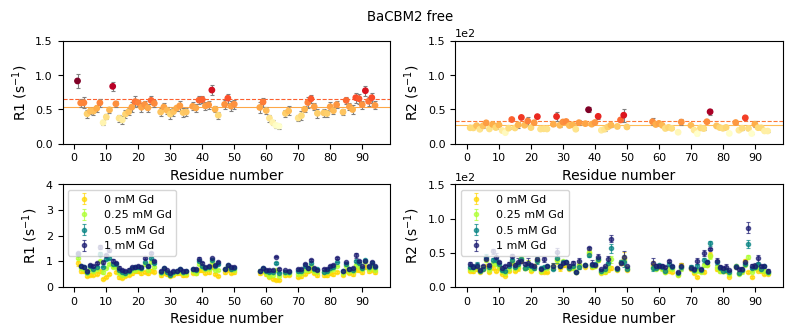

In [50]:
#BaCBM2
width_mm = 200
width_in = width_mm / 25.4 
height_in = width_in * 0.4
fig, ax = plt.subplots(2, 2, figsize =((width_in,height_in)), sharey = False)
fig.tight_layout()
fig.subplots_adjust(top=0.88)
fig.subplots_adjust(hspace=0.4)
fig.subplots_adjust(wspace=0.2)
fig.suptitle("BaCBM2 free")

# R1
dfs = [T1_Ba_free_0]
dfs = [df.drop([0, 1]) for df in dfs]
list_of_legends = ['BaCBM2 0mM Gd']
colormaps = ["YlOrRd"]
plot_R(dfs, list_of_legends, (0,1.5), 'R1', ax[0,0], colormaps = colormaps)
show_colored_sequence(sequence_Ba, dfs[0], colormaps[0], 'R')
pymol_colors(dfs[0], colormaps[0], 'R', 'R1_Ba_free')

# R1 - with Gd
dfs = [T1_Ba_free_0, T1_Ba_free_025, T1_Ba_free_05, T1_Ba_free_075]
dfs = [df.drop([0, 1]) for df in dfs]
list_of_legends = ['0 mM Gd', '0.25 mM Gd', '0.5 mM Gd', '1 mM Gd']
list_of_colors = ['gold', 'greenyellow', 'teal', 'midnightblue']
plot_R(dfs, list_of_legends, (0,4), 'R1', ax[1,0], list_of_colors)

ax[1,0].yaxis.set_major_locator(ticker.MultipleLocator(1))
ax[1,0].legend(loc = 'upper left')

# R2
dfs = [T2_Ba_free_0]
dfs = [df.drop([0, 1]) for df in dfs]
list_of_legends = ['BaCBM2 0mM Gd']
colormaps = ["YlOrRd"]
plot_R(dfs, list_of_legends, (0,150), 'R2', ax[0,1], colormaps = colormaps)
show_colored_sequence(sequence_Ba, dfs[0], colormaps[0], 'R')
pymol_colors(dfs[0], colormaps[0], 'R', 'R2_Ba_free')
ax[0,1].yaxis.set_major_locator(ticker.MultipleLocator(50))
ax[0,1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

# R2 - with Gd
dfs = [T2_Ba_free_0, T2_Ba_free_025, T2_Ba_free_05, T2_Ba_free_075]
dfs = [df.drop([0, 1]) for df in dfs]
list_of_legends = ['0 mM Gd', '0.25 mM Gd', '0.5 mM Gd', '1 mM Gd']
list_of_colors = ['gold', 'greenyellow', 'teal', 'midnightblue']
plot_R(dfs, list_of_legends, (0,150), 'R2', ax[1,1], list_of_colors)
ax[1,1].yaxis.set_major_locator(ticker.MultipleLocator(50))
ax[1,1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax[1,1].legend(loc = 'upper left')

plt.savefig('Plots/Relax_BaCBM2_free.svg', bbox_inches='tight')

Using colormap branch
Using colormap branch


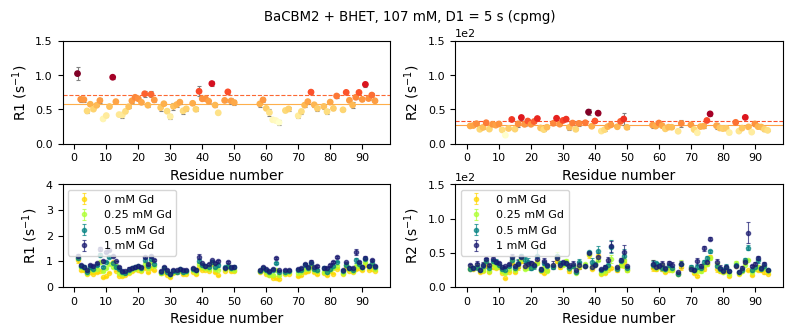

In [51]:
#BaCBM2 BHET
width_mm = 200
width_in = width_mm / 25.4 
height_in = width_in * 0.4
fig, ax = plt.subplots(2, 2, figsize =((width_in,height_in)), sharey = False)
fig.tight_layout()
fig.subplots_adjust(top=0.88)
fig.subplots_adjust(hspace=0.4)
fig.subplots_adjust(wspace=0.2)
fig.suptitle("BaCBM2 + BHET, 107 mM, D1 = 5 s (cpmg)")

# R1
dfs = [T1_Ba_bhet_0]
dfs = [df.drop([0, 1]) for df in dfs]
list_of_legends = ['BaCBM2 0mM Gd']
colormaps = ["YlOrRd"]
plot_R(dfs, list_of_legends, (0,1.5), 'R1', ax[0,0], colormaps = colormaps)

# R1 - with Gd
dfs = [T1_Ba_bhet_0, T1_Ba_bhet_025, T1_Ba_bhet_05, T1_Ba_bhet_075]
dfs = [df.drop([0, 1]) for df in dfs]
list_of_legends = ['0 mM Gd', '0.25 mM Gd', '0.5 mM Gd', '1 mM Gd']
list_of_colors = ['gold', 'greenyellow', 'teal', 'midnightblue']
plot_R(dfs, list_of_legends, (0,4), 'R1', ax[1,0], list_of_colors)
ax[1,0].yaxis.set_major_locator(ticker.MultipleLocator(1))
ax[1,0].legend(loc = 'upper left')

# R2
dfs = [T2_Ba_bhet_0]
dfs = [df.drop([0, 1]) for df in dfs]
list_of_legends = ['BaCBM2 0mM Gd']
colormaps = ["YlOrRd"]
plot_R(dfs, list_of_legends, (0,150), 'R2', ax[0,1], colormaps = colormaps)
ax[0,1].yaxis.set_major_locator(ticker.MultipleLocator(50))
ax[0,1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

# R2 - with Gd
dfs = [T2_Ba_bhet_0, T2_Ba_bhet_025, T2_Ba_bhet_05, T2_Ba_bhet_075]
dfs = [df.drop([0, 1]) for df in dfs]
list_of_legends = ['0 mM Gd', '0.25 mM Gd', '0.5 mM Gd', '1 mM Gd']
list_of_colors = ['gold', 'greenyellow', 'teal', 'midnightblue']
plot_R(dfs, list_of_legends, (0,150), 'R2', ax[1,1], list_of_colors)
ax[1,1].yaxis.set_major_locator(ticker.MultipleLocator(50))
ax[1,1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax[1,1].legend(loc = 'upper left')

plt.savefig('Plots/Relax_BaCBM2_BHET.svg', bbox_inches='tight')

Using colormap branch
Using colormap branch


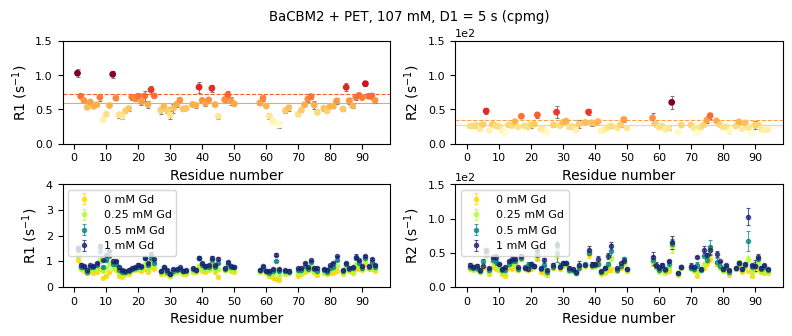

In [52]:
#BaCBM2 PET
width_mm = 200
width_in = width_mm / 25.4 
height_in = width_in * 0.4
fig, ax = plt.subplots(2, 2, figsize =((width_in,height_in)), sharey = False)
fig.tight_layout()
fig.subplots_adjust(top=0.88)
fig.subplots_adjust(hspace=0.4)
fig.subplots_adjust(wspace=0.2)
fig.suptitle("BaCBM2 + PET, 107 mM, D1 = 5 s (cpmg)")

# R1
dfs = [T1_Ba_pet_0]
dfs = [df.drop([0, 1]) for df in dfs]
list_of_legends = ['BaCBM2 0mM Gd']
colormaps = ["YlOrRd"]
plot_R(dfs, list_of_legends, (0,1.5), 'R1', ax[0,0], colormaps = colormaps)

# R1 - with Gd
dfs = [T1_Ba_pet_0, T1_Ba_pet_025, T1_Ba_pet_05, T1_Ba_pet_075]
dfs = [df.drop([0, 1]) for df in dfs]
list_of_legends = ['0 mM Gd', '0.25 mM Gd', '0.5 mM Gd', '1 mM Gd']
list_of_colors = ['gold', 'greenyellow', 'teal', 'midnightblue']
plot_R(dfs, list_of_legends, (0,4), 'R1', ax[1,0], list_of_colors)
ax[1,0].yaxis.set_major_locator(ticker.MultipleLocator(1))
ax[1,0].legend(loc = 'upper left')

# R2
dfs = [T2_Ba_pet_0]
dfs = [df.drop([0, 1]) for df in dfs]
list_of_legends = ['BaCBM2 0mM Gd']
colormaps = ["YlOrRd"]
plot_R(dfs, list_of_legends, (0,150), 'R2', ax[0,1], colormaps = colormaps)
ax[0,1].yaxis.set_major_locator(ticker.MultipleLocator(50))
ax[0,1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

# R2 - with Gd
dfs = [T2_Ba_pet_0, T2_Ba_pet_025, T2_Ba_pet_05, T2_Ba_pet_075]
dfs = [df.drop([0, 1]) for df in dfs]
list_of_legends = ['0 mM Gd', '0.25 mM Gd', '0.5 mM Gd', '1 mM Gd']
list_of_colors = ['gold', 'greenyellow', 'teal', 'midnightblue']
plot_R(dfs, list_of_legends, (0,150), 'R2', ax[1,1], list_of_colors)
ax[1,1].yaxis.set_major_locator(ticker.MultipleLocator(50))
ax[1,1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax[1,1].legend(loc = 'upper left')

plt.savefig('Plots/Relax_BaCBM2_PET.svg', bbox_inches='tight')

## sPRE
Calculate PRE from relaxation data

In [53]:
def calc_PRE(dfs, list_of_conc):
    df = pd.merge(
        dfs[0][['AA_no', 'R', 'R_err']],
        dfs[1][['AA_no', 'R', 'R_err']],
        on='AA_no',
        suffixes=('_0', '_1')
    )

    df2 = dfs[2][['AA_no', 'R', 'R_err']].rename(columns={'R': 'R_2', 'R_err': 'R_err_2'})
    df3 = dfs[3][['AA_no', 'R', 'R_err']].rename(columns={'R': 'R_3', 'R_err': 'R_err_3'})
    df = pd.merge(df, df2, on='AA_no')
    df = pd.merge(df, df3, on='AA_no')

    df = df.replace([np.inf, -np.inf], np.nan).dropna()

    #Calculate PRE using polyfit, add to dataframe
    x = np.array(list_of_conc)
    R = df[[f'R_{i}' for i in range(4)]].to_numpy()
    Rerr = df[[f'R_err_{i}' for i in range(4)]].to_numpy()

    # output arrays
    a = np.full(len(df), np.nan)
    b = np.full(len(df), np.nan)
    a_err = np.full(len(df), np.nan)

    #regression per residue
    for i in range(len(df)):

        y = R[i]
        sd = Rerr[i]

        mask = np.isfinite(y) & np.isfinite(sd)

        if mask.sum() < 2:
            continue

        p, cov = np.polyfit(x[mask], y[mask], deg=1, w=1/sd[mask], cov=True)
        a[i] = p[0]
        b[i] = p[1]
        a_err[i] = np.sqrt(cov[0, 0])

    df['a'] = a
    df['b'] = b
    df['a_err'] = a_err

    return df
    
def plot_PRE_residues(df, residues, list_of_conc):
    x = np.array(list_of_conc)
    n = len(list_of_conc)

    fig, ax = plt.subplots()
    colors = ['firebrick', 'olivedrab', 'lightseagreen', 'mediumpurple', 'cornflowerblue', 'peru', 'black', 'blue', 'orange', 'yellowgreen', 'plum', 'violet', 'gold', 'tomato', 'skyblue', 'magenta']
    i = 0
    for resi in residues:
        row = df[df["AA_no"] == resi]
        if row.empty:
            print(f"Residue {resi} not found")
            continue
        # extract y values
        y = row[[f"R_{i}" for i in range(n)]].values.flatten()
        y_err = row[[f"R_err_{i}" for i in range(n)]].values.flatten()
        # skip if missing data
        mask = np.isfinite(y)
        if mask.sum() < 2:
            continue

        # linear fit
        p = np.polyfit(x[mask], y[mask], 1)
        y_fit = np.polyval(p, x)

        # plot
        ax.errorbar(x, y, yerr = y_err, fmt = 'o', c=colors[i], elinewidth=0.8, capsize=1.5, capthick=0.8, label=f"Res {resi}")
        ax.plot(x, y_fit, linestyle='--', c=colors[i])
        i += 1

    ax.set_xlabel("Gd concentration")
    ax.set_ylabel("R")
    ax.legend()

def plot_PRE(dfs, list_of_legends, ylim, R1R2, ax, list_of_colors=None, colormaps=None):
        
    plt.rcParams.update({
        "font.size": 8,        # base font size
        "axes.labelsize": 10,   # axis labels
        "xtick.labelsize": 8,  # x tick labels
        "ytick.labelsize": 8,  # y tick labels
        "legend.fontsize": 8,  # legend
    })
    
    width_mm = 130
    width_in = width_mm / 25.4 
    height_in = width_in * 0.5

    #define colors
    if list_of_colors is not None:    
        ax.set_prop_cycle(color=list_of_colors)
        for i in range(len(dfs)):
            ax.errorbar(dfs[i]['AA_no'], dfs[i]['a'], yerr = dfs[i]['a_err'], fmt='.', elinewidth=0.8, capsize=1.5, capthick=0.8, alpha = 0.7, label = list_of_legends[i])

    elif colormaps is not None:
        print("Using colormap branch")
        for i in range(len(dfs)):
            cmap, norm, colors, avg, std = get_colors(dfs[i], colormaps[i], 'a')
            x = dfs[i]['AA_no']
            y = dfs[i]['a']
            yerr = dfs[i]['a_err']

            ax.axhline(avg+std, color = cmap(norm(avg+std)), linewidth = 0.8, linestyle = '--', zorder=0)
            ax.axhline(avg, color = cmap(norm(avg)), linewidth = 0.8, zorder=0)
            ax.errorbar(x, y, yerr = yerr, fmt='none', ecolor='gray', elinewidth=0.8, capsize=1.5, capthick=0.8, zorder=1)
            ax.scatter(x, y, c=colors, s=15, label = list_of_legends[i], zorder=2)
            
    else:
        for i in range(len(dfs)):
            ax.errorbar(dfs[i]['AA_no'], dfs[i]['a'], yerr = dfs[i]['a'], fmt='.', elinewidth=0.8, capsize=1.5, capthick=0.8, alpha = 0.7, label = list_of_legends[i])
    
    if R1R2 == 'R1':
        ax.set_ylabel('R1 PRE')
        ax.yaxis.set_major_locator(ticker.MultipleLocator(0.5))
    elif R1R2 == 'R2':
        ax.set_ylabel('R2 PRE')
        ax.yaxis.set_major_locator(ticker.MultipleLocator(5))
        
    ax.set_xlabel('Residue number')
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.set_ylim(ylim)

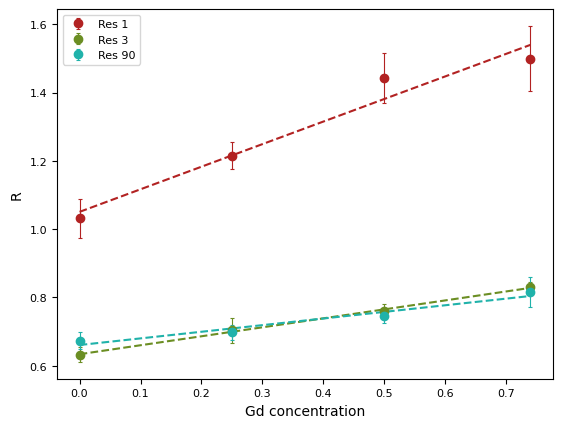

In [54]:
#Visualize PRE calculation. PRE is slope of regression line
dfs = [T1_Ba_pet_0, T1_Ba_pet_025, T1_Ba_pet_05, T1_Ba_pet_075]
conc = [0, 0.25, 0.5, 0.74]
df = calc_PRE(dfs, conc)

residues = [1, 3, 90]
plot_PRE_residues(df, residues, conc)

Using colormap branch

------------PRE_R1_BaCBM2_free------------------
Average CSP: 0.3814
Std Dev:     0.2594

Residues above average:
[1, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 22, 23, 24, 25, 39, 44, 45, 61, 62, 63, 64, 70, 72, 74, 81, 82, 88, 89]
Residues above average + std:
[8, 9, 10, 11, 22, 24, 45, 63, 82, 88]

PyMOL commands:
select high_PRE_R1_BaCBM2_free, PRE_R1_BaCBM2_free and resi 1+5+6+7+8+9+10+11+13+14+15+22+23+24+25+39+44+45+61+62+63+64+70+72+74+81+82+88+89
select high_std_PRE_R1_BaCBM2_free, PRE_R1_BaCBM2_free and resi 8+9+10+11+22+24+45+63+82+88

Using colormap branch

------------PRE_R2_BaCBM2_free------------------
Average CSP: 10.8068
Std Dev:     12.8467

Residues above average:
[1, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 20, 24, 25, 28, 43, 44, 45, 63, 64, 72, 74, 76, 78, 82, 88, 89, 91, 93]
Residues above average + std:
[8, 9, 45, 72, 74, 88, 89]

PyMOL commands:
select high_PRE_R2_BaCBM2_free, PRE_R2_BaCBM2_free and resi 1+6+7+8+9+10+11+12+13+14+15+16+20+24+25+28+

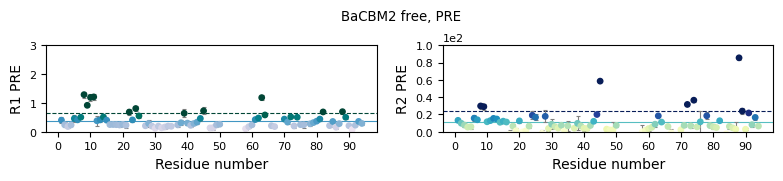

In [55]:
#plot PRE
width_mm = 200
width_in = width_mm / 25.4 
height_in = width_in * 0.2
fig, ax = plt.subplots(1, 2, figsize =((width_in,height_in)), sharey = False)
fig.tight_layout()
fig.subplots_adjust(top=0.75)
fig.subplots_adjust(hspace=0.4)
fig.subplots_adjust(wspace=0.2)
fig.suptitle("BaCBM2 free, PRE")

conc = [0, 0.25, 0.5, 0.74]

# R1
dfs = [T1_Ba_free_0, T1_Ba_free_025, T1_Ba_free_05, T1_Ba_free_075]
dfs = [df.drop([0, 1]) for df in dfs]
df = [calc_PRE(dfs, conc)]
list_of_legends = ['BaCBM2 free']
colormaps = ["PuBuGn"]
plot_PRE(df, list_of_legends, (0,3), 'R1', ax[0], colormaps = colormaps)
pymol_colors(df[0], colormaps[0], 'a', 'PRE_R1_BaCBM2_free')
ax[0].yaxis.set_major_locator(ticker.MultipleLocator(1))

# R2
dfs = [T2_Ba_free_0, T2_Ba_free_025, T2_Ba_free_05, T2_Ba_free_075]
dfs = [df.drop([0, 1]) for df in dfs]
df = [calc_PRE(dfs, conc)]
list_of_legends = ['BaCBM2 free']
colormaps = ["YlGnBu"]
plot_PRE(df, list_of_legends, (0,100), 'R2', ax[1], colormaps = colormaps)
pymol_colors(df[0], colormaps[0], 'a', 'PRE_R2_BaCBM2_free')
ax[1].yaxis.set_major_locator(ticker.MultipleLocator(20))
ax[1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

plt.savefig('Plots/PRE_BaCBM2.svg', bbox_inches='tight')

Using colormap branch
Using colormap branch


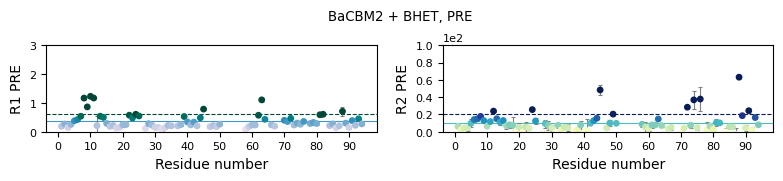

In [56]:
width_mm = 200
width_in = width_mm / 25.4 
height_in = width_in * 0.2
fig, ax = plt.subplots(1, 2, figsize =((width_in,height_in)), sharey = False)
fig.tight_layout()
fig.subplots_adjust(top=0.75)
fig.subplots_adjust(hspace=0.4)
fig.subplots_adjust(wspace=0.2)
fig.suptitle("BaCBM2 + BHET, PRE")

conc = [0, 0.25, 0.5, 0.74]

# R1
dfs = [T1_Ba_bhet_0, T1_Ba_bhet_025, T1_Ba_bhet_05, T1_Ba_bhet_075]
dfs = [df.drop([0, 1]) for df in dfs]
df = [calc_PRE(dfs, conc)]
list_of_legends = ['BaCBM2 BHET']
colormaps = ["PuBuGn"]
plot_PRE(df, list_of_legends, (0,3), 'R1', ax[0], colormaps = colormaps)
ax[0].yaxis.set_major_locator(ticker.MultipleLocator(1))

# R2
dfs = [T2_Ba_bhet_0, T2_Ba_bhet_025, T2_Ba_bhet_05, T2_Ba_bhet_075]
dfs = [df.drop([0, 1]) for df in dfs]
df = [calc_PRE(dfs, conc)]
list_of_legends = ['BaCBM2 BHET']
colormaps = ["YlGnBu"]
plot_PRE(df, list_of_legends, (0,100), 'R2', ax[1], colormaps = colormaps)
ax[1].yaxis.set_major_locator(ticker.MultipleLocator(20))
ax[1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

plt.savefig('Plots/PRE_BaCBM2_BHET.svg', bbox_inches='tight')

Using colormap branch
Using colormap branch


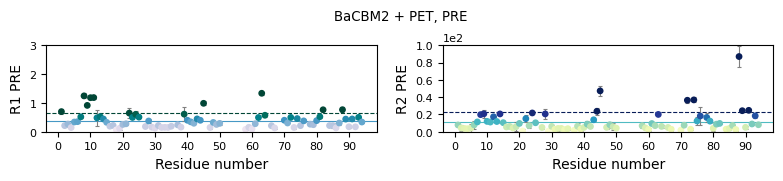

In [57]:
width_mm = 200
width_in = width_mm / 25.4 
height_in = width_in * 0.2
fig, ax = plt.subplots(1, 2, figsize =((width_in,height_in)), sharey = False)
fig.tight_layout()
fig.subplots_adjust(top=0.75)
fig.subplots_adjust(hspace=0.4)
fig.subplots_adjust(wspace=0.2)
fig.suptitle("BaCBM2 + PET, PRE")

conc = [0, 0.25, 0.5, 0.74]

# R1
dfs = [T1_Ba_pet_0, T1_Ba_pet_025, T1_Ba_pet_05, T1_Ba_pet_075]
dfs = [df.drop([0, 1]) for df in dfs]
df = [calc_PRE(dfs, conc)]
list_of_legends = ['BaCBM2 PET']
colormaps = ["PuBuGn"]
plot_PRE(df, list_of_legends, (0,3), 'R1', ax[0], colormaps = colormaps)
ax[0].yaxis.set_major_locator(ticker.MultipleLocator(1))

# R2
dfs = [T2_Ba_pet_0, T2_Ba_pet_025, T2_Ba_pet_05, T2_Ba_pet_075]
dfs = [df.drop([0, 1]) for df in dfs]
df = [calc_PRE(dfs, conc)]
list_of_legends = ['BaCBM2 PET']
colormaps = ["YlGnBu"]
plot_PRE(df, list_of_legends, (0,100), 'R2', ax[1], colormaps = colormaps)
ax[1].yaxis.set_major_locator(ticker.MultipleLocator(20))
ax[1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

plt.savefig('Plots/PRE_BaCBM2_PET.svg', bbox_inches='tight')

Using colormap branch

------------PRE_R1_ScCBM2_free------------------
Average CSP: 0.9350
Std Dev:     1.0064

Residues above average:
[2, 12, 15, 28, 32, 42, 46, 47, 48, 51, 54, 56, 57, 60, 61, 68, 73, 88, 89, 90, 91, 96, 97, 99]
Residues above average + std:
[2, 12, 15, 28, 32, 42, 48, 51, 54, 57, 60, 73, 90, 96, 99]

PyMOL commands:
select high_PRE_R1_ScCBM2_free, PRE_R1_ScCBM2_free and resi 2+12+15+28+32+42+46+47+48+51+54+56+57+60+61+68+73+88+89+90+91+96+97+99
select high_std_PRE_R1_ScCBM2_free, PRE_R1_ScCBM2_free and resi 2+12+15+28+32+42+48+51+54+57+60+73+90+96+99

Using colormap branch

------------PRE_R2_ScCBM2_free------------------
Average CSP: 11.7455
Std Dev:     23.4440

Residues above average:
[9, 12, 13, 17, 18, 23, 25, 26, 27, 32, 34, 36, 37, 41, 46, 47, 48, 49, 50, 55, 56, 57, 69, 73, 83, 84, 85, 89, 91, 92, 95, 97, 98]
Residues above average + std:
[12, 13, 36, 48, 56, 57, 91]

PyMOL commands:
select high_PRE_R2_ScCBM2_free, PRE_R2_ScCBM2_free and resi 9+12+13+17+18

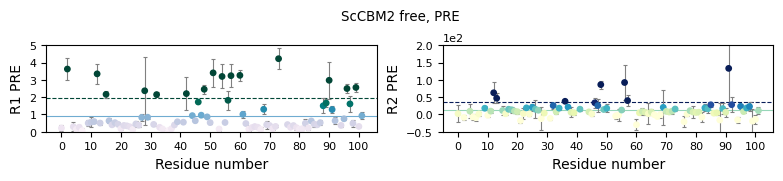

In [58]:
width_mm = 200
width_in = width_mm / 25.4 
height_in = width_in * 0.2
fig, ax = plt.subplots(1, 2, figsize =((width_in,height_in)), sharey = False)
fig.tight_layout()
fig.subplots_adjust(top=0.75)
fig.subplots_adjust(hspace=0.4)
fig.subplots_adjust(wspace=0.2)
fig.suptitle("ScCBM2 free, PRE")

conc = [0, 0.25, 0.5, 0.98]

# R1
dfs = [T1_Sc_free_0, T1_Sc_free_025, T1_Sc_free_05, T1_Sc_free_1]
df = [calc_PRE(dfs, conc)]
list_of_legends = ['ScCBM2 free']
colormaps = ["PuBuGn"]
plot_PRE(df, list_of_legends, (0,5), 'R1', ax[0], colormaps = colormaps)
pymol_colors(df[0], colormaps[0], 'a', 'PRE_R1_ScCBM2_free')
ax[0].yaxis.set_major_locator(ticker.MultipleLocator(1))

# R2
dfs = [T2_Sc_free_0, T2_Sc_free_025, T2_Sc_free_05, T2_Sc_free_1]
df = [calc_PRE(dfs, conc)]
df[0] = df[0][df[0]["AA_no"] != 51]
list_of_legends = ['ScCBM2 free']
colormaps = ["YlGnBu"]
plot_PRE(df, list_of_legends, (-50,200), 'R2', ax[1], colormaps = colormaps)
pymol_colors(df[0], colormaps[0], 'a', 'PRE_R2_ScCBM2_free')
ax[1].yaxis.set_major_locator(ticker.MultipleLocator(50))
ax[1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

plt.savefig('Plots/PRE_ScCBM2.svg', bbox_inches='tight')

## Changes in relaxation rates and sPRE upon substrate binding

In [59]:
#relaxation
R1_bhet_Ba = [T1_Ba_free_0, T1_Ba_bhet_0]
R2_bhet_Ba = [T2_Ba_free_0, T2_Ba_bhet_0]

R1_pet_Ba = [T1_Ba_free_0, T1_Ba_pet_0]
R2_pet_Ba = [T2_Ba_free_0, T2_Ba_pet_0]

#PRE                                                   

# PRE_R1_bhet_Ba
conc = [0, 0.25, 0.5, 0.74]
dfs = [T1_Ba_free_0, T1_Ba_free_025, T1_Ba_free_05, T1_Ba_free_075]
dfs = [df.drop([0, 1]) for df in dfs]
df_free = calc_PRE(dfs, conc)
dfs = [T1_Ba_bhet_0, T1_Ba_bhet_025, T1_Ba_bhet_05, T1_Ba_bhet_075]
dfs = [df.drop([0, 1]) for df in dfs]
df_bound = calc_PRE(dfs, conc)
PRE_R1_bhet_Ba = [df_free, df_bound]  

# PRE_R2_bhet_Ba
dfs = [T2_Ba_free_0, T2_Ba_free_025, T2_Ba_free_05, T2_Ba_free_075]
dfs = [df.drop([0, 1]) for df in dfs]
df_free = calc_PRE(dfs, conc)
dfs = [T2_Ba_bhet_0, T2_Ba_bhet_025, T2_Ba_bhet_05, T2_Ba_bhet_075]
dfs = [df.drop([0, 1]) for df in dfs]
df_bound = calc_PRE(dfs, conc)
PRE_R2_bhet_Ba = [df_free, df_bound]

# PRE_R1_pet_Ba
dfs = [T1_Ba_free_0, T1_Ba_free_025, T1_Ba_free_05, T1_Ba_free_075]
dfs = [df.drop([0, 1]) for df in dfs]
df_free = calc_PRE(dfs, conc)
dfs = [T1_Ba_pet_0, T1_Ba_pet_025, T1_Ba_pet_05, T1_Ba_pet_075]
dfs = [df.drop([0, 1]) for df in dfs]
df_bound = calc_PRE(dfs, conc)
PRE_R1_pet_Ba = [df_free, df_bound]

# PRE_R2_pet_Ba
dfs = [T2_Ba_free_0, T2_Ba_free_025, T2_Ba_free_05, T2_Ba_free_075]
dfs = [df.drop([0, 1]) for df in dfs]
df_free = calc_PRE(dfs, conc)
dfs = [T2_Ba_pet_0, T2_Ba_pet_025, T2_Ba_pet_05, T2_Ba_pet_075]
dfs = [df.drop([0, 1]) for df in dfs]
df_bound = calc_PRE(dfs, conc)
PRE_R2_pet_Ba = [df_free, df_bound]



In [60]:
def calc_dR(dfs):
    df_free = dfs[0]
    df_bound = dfs[1]
    df = pd.merge(
        df_free[['AA_no', 'R', 'R_err']],
        df_bound[['AA_no', 'R', 'R_err']],
        on='AA_no',
        how='inner',
        suffixes=('_free', '_bound')
    )
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    
    df['delta_R'] = df['R_bound'] - df['R_free']
    df['delta_R_err'] = np.sqrt(df['R_err_free']**2 + df['R_err_bound']**2)
    df['rel_delta_R'] = df['R_bound'] / df['R_free']
    df['rel_delta_R_err'] = df['rel_delta_R'] * np.sqrt((df['R_err_bound'] / df['R_bound'])**2 + (df['R_err_free'] / df['R_free'])**2)
    
    return df
    
def calc_dPRE(dfs):
    df_free = dfs[0]
    df_bound = dfs[1]    

    df = pd.merge(
        df_free[['AA_no', 'a', 'a_err']],
        df_bound[['AA_no', 'a', 'a_err']],
        on='AA_no',
        how='inner',
        suffixes=('_free', '_bound')
    )
    df = df.replace([np.inf, -np.inf], np.nan).dropna()

    df['delta_a'] = df['a_bound'] - df['a_free']
    df['delta_a_err'] = np.sqrt(df['a_err_free']**2 + df['a_err_bound']**2)
    df['rel_delta_a'] = df['a_bound'] / df['a_free']
    df['rel_delta_a_err'] = np.abs(df['rel_delta_a']) * np.sqrt((df['a_err_bound'] / df['a_bound'])**2 + (df['a_err_free'] / df['a_free'])**2)
    
    return df

def print_specific_values(df, plot_title):
    if 'delta_R' in df.columns:
        delta = df['delta_R']
        rel_delta = df['rel_delta_R']
    elif 'delta_a' in df.columns:
        delta = df['delta_a']
        rel_delta = df['rel_delta_a']
    
    if 'Sc' in plot_title:
        W13 = delta.loc[df['AA_no'] == 13].iloc[0]
        W50 = delta.loc[df['AA_no'] == 50].iloc[0]
        H69 = delta.loc[df['AA_no'] == 69].iloc[0]
        print(f'W13: {W13:.3f}, W50: {W50:.3f}, H69: {H69:.3f}')
        W13 = rel_delta.loc[df['AA_no'] == 13].iloc[0]
        W50 = rel_delta.loc[df['AA_no'] == 50].iloc[0]
        H69 = rel_delta.loc[df['AA_no'] == 69].iloc[0]
        print(f'relative: W13: {W13:.3f}, W50: {W50:.3f}, H69: {H69:.3f}')
    
    elif 'Ba' in plot_title:
        W9 = delta.loc[df['AA_no'] == 9].iloc[0]
        W44 = delta.loc[df['AA_no'] == 44].iloc[0]
        W63 = delta.loc[df['AA_no'] == 63].iloc[0]
        print(f'W9: {W9:.3f}, W44: {W44:.3f}, W63: {W63:.3f}')
        W9 = rel_delta.loc[df['AA_no'] == 9].iloc[0]
        W44 = rel_delta.loc[df['AA_no'] == 44].iloc[0]
        W63 = rel_delta.loc[df['AA_no'] == 63].iloc[0]
        print(f'relative: W9: {W9:.3f}, W44: {W44:.3f}, W63: {W63:.3f}')

def calc_dR_dPRE(data, plot_title, textfile, print_details=False):
    # R1 relaxation 
    df = calc_dR(data[0])
    average_relaxation_free = df['R_free'].mean()
    average_relaxation_bound = df['R_bound'].mean()
    average_delta_R = df['delta_R'].mean()
    average_rel_delta_R = df['rel_delta_R'].mean()
    deltaR1 = df

    if print_details == True:
        with open(textfile, "a") as f:
            print(f"-----R1, {plot_title}-----", file=f)
            print('Average relaxation rate for the free state is ' + str(average_relaxation_free), file=f)
            print('Average relaxation rate for the bound state is ' + str(average_relaxation_bound), file=f)
            print('Average delta R ' + str(average_delta_R), file=f)
            print('Average relative delta R ' + str(average_rel_delta_R), file=f)
        print_specific_values(df, plot_title)

    #R2 relaxation 
    df = calc_dR(data[1])
    average_relaxation_free = df['R_free'].mean()
    average_relaxation_bound = df['R_bound'].mean()
    average_delta_R = df['delta_R'].mean()
    average_rel_delta_R = df['rel_delta_R'].mean()
    deltaR2 = df

    if print_details == True:
        with open(textfile, "a") as f:
            print(f"-----R2, {plot_title}-----", file=f)
            print('Average relaxation rate for the free state is ' + str(average_relaxation_free), file=f)
            print('Average relaxation rate for the bound state is ' + str(average_relaxation_bound), file=f)
            print('Average delta R ' + str(average_delta_R), file=f)
            print('Average relative delta R ' + str(average_rel_delta_R), file=f)
        print_specific_values(df, plot_title)

    # R1 PRE:
    df = calc_dPRE(data[2])
    average_PRE_free = df['a_free'].mean()
    average_PRE_bound = df['a_bound'].mean()
    average_delta_PRE = df['delta_a'].mean()
    average_rel_delta_PRE = df['rel_delta_a'].mean()
    deltaPRE_R1 = df

    if print_details == True:
        with open(textfile, "a") as f:
            print(f"-----R1 PRE, {plot_title}-----", file=f)
            print('Average PRE for the free state is ' + str(average_PRE_free), file=f)
            print('Average PRE for the bound state is ' + str(average_PRE_bound), file=f)
            print('Average delta PRE ' + str(average_delta_PRE), file=f)
            print('Average relative delta PRE ' + str(average_rel_delta_PRE), file=f)
        print_specific_values(df, plot_title)

    # R2 PRE:
    df = calc_dPRE(data[3])
    average_PRE_free = df['a_free'].mean()
    average_PRE_bound = df['a_bound'].mean()
    average_delta_PRE = df['delta_a'].mean()
    average_rel_delta_PRE = df['rel_delta_a'].mean()
    deltaPRE_R2 = df

    if print_details == True:
        with open(textfile, "a") as f:
            print(f"-----R2 PRE, {plot_title}-----", file=f)
            print('Average PRE for the free state is ' + str(average_PRE_free), file=f)
            print('Average PRE for the bound state is ' + str(average_PRE_bound), file=f)
            print('Average delta PRE ' + str(average_delta_PRE), file=f)
            print('Average relative delta PRE ' + str(average_rel_delta_PRE), file=f)
        print_specific_values(df, plot_title)

    
    return deltaR1, deltaR2, deltaPRE_R1, deltaPRE_R2

In [61]:
def plot_free_vs_bound(df, ax, plot_title, name):
    prot, sub = plot_title.split()
    
    x = df.iloc[:,0]
    y1 = df.iloc[:,1]
    y1_err = df.iloc[:,2]

    y2 = df.iloc[:,3]
    y2_err = df.iloc[:,4]

    if name == 'R1':
        ylim = (0,1.5)
        ytitle = 'R1 (s$^{-1}$)'
    elif name == 'R2':
        ylim = (0,300)
        ytitle = 'R2 (s$^{-1}$)'
    
    elif name == 'PRE_R1':
        ylim = (0,5)
        ytitle = 'sPRE R1 (s$^{-1}$ mM$^{-1}$)'
    elif name == 'PRE_R2':
        ylim = (-150,200)
        ytitle = 'sPRE R2 (s$^{-1}$ mM$^{-1}$)'

    
    ax.errorbar(x, y1, yerr = y1_err, fmt='.', color = 'black', elinewidth=0.8, capsize=1.5, capthick=0.8, alpha = 0.5, label = f'{prot}')
    ax.errorbar(x, y2, yerr = y2_err, fmt='.', color = 'blue', elinewidth=0.8, capsize=1.5, capthick=0.8, alpha = 0.5, label = f'{prot} + {sub}')
    ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
    ax.legend(frameon=False)
    #ax.set_ylim(ylim)
    ax.set_ylabel(ytitle)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))

def show_colored_sequence_2(x, y, plot_title, colormap, gradient_limits):

    if 'Sc' in plot_title:
        sequence = 'GSCMAVYSVENSWSGGFQGSVEVMNHGTEPLNGWAVQWQPGGGTTLGGVWNGSLTSGSDGTVTVRNVDHNRVVPPDGSVTFGFTATSTGNDFPVDSIGCVAP'
    elif 'Ba' in plot_title:
        sequence = 'ATFSVTSNWGSGYNFSIVIKNSGTTPIKNWKLEFDYNGNLTQVWDSKISSKINNHYVITNAGWNGEIPPGGSITIGGAGTGTPAELVNASISEN'
    else:
        raise ValueError("plot_title must contain 'Sc' or 'Ba'")

    # Create colormap based on y values
    cmap = plt.get_cmap(colormap)
    #norm = mcolors.Normalize(vmin=min(y), vmax=max(y))
    norm = mcolors.Normalize(vmin=gradient_limits[0], vmax=gradient_limits[1])
    colors = cmap(norm(y))
    colors = [to_hex(c) for c in colors]

    # Create dictionary: residue number -> color
    color_dict = dict(zip(x, colors))

    html_seq = ""

    for i, aa in enumerate(sequence, start=1):
        # Use color if residue exists in x, otherwise grey
        color = color_dict.get(i, "#B5B3B3")

        html_seq += (
            f"<span style='color:{color}; font-family:monospace;'>"
            f"{aa}</span>"
        )

    display(HTML(html_seq))

    return cmap(norm(y))

def pymol_colors_change(x, y, colors, plot_title):
    prot, sub, r = plot_title.split()
    label = f'{prot}_{sub}_{r}'

    #pymol coloring
    rgb_colors = {}
    for resi, value in zip(x, colors):
        r, g, b, _ = value
        rgb_colors[int(resi)] = (r, g, b)

    
    filename = f"pymol_changes/pymol_colors_{label}.pml"
    with open(filename, "w") as f:
        if 'Sc' in label:
            f.write(f"set_name fold_sccbm2_model_0, {label}\n")
        elif 'Ba' in label: 
            f.write(f"set_name fold_bacbm2_model_0, {label}\n")

        f.write(f"color white, {label}\n")
        for resi, (r, g, b) in rgb_colors.items():
            color_name = f"c_{resi}_{label}"
    
            f.write(
                f"set_color {color_name}, [{r:.4f}, {g:.4f}, {b:.4f}]\n"
            )
            f.write(
                f"color {color_name}, {label} and resi {resi}\n"
            )


def plot_change(df, ax, plot_title, name, textfile, rel = False):
    #prot, sub = plot_title.split()
    
    
    #remove points with very high error
    threshold = df.iloc[:,6].mean() * 2
    outliers = df[df.iloc[:,6] > threshold]
    df = df[df.iloc[:,6] <= threshold]
    
    x = df.iloc[:,0]
    y = df.iloc[:,5]
    y_err = df.iloc[:,6]

    if name == 'R1':
        ylim = (-0.4,0.4)
        ytitle = '$\Delta$R1 (s$^{-1}$)'
        gradient_limits = [-0.1,0.1]
    elif name == 'R2':
        ylim = (-30,30)
        ytitle = '$\Delta$R2 (s$^{-1}$)'
        gradient_limits = [-10,10]
    
    elif name == 'PRE_R1':
        ylim = (-1,1)
        ytitle = '$\Delta$sPRE R1'
        gradient_limits = [-0.5,0.5]
    elif name == 'PRE_R2':
        ylim = (-30,30)
        ytitle = '$\Delta$sPRE R2'
        gradient_limits = [-20,20]

    if 'Sc' in plot_title:
        if name == 'R1':
            ylim = (-1,1)
            ytitle = '$\Delta$R1 (s$^{-1}$)'
            gradient_limits = [-0.2,0.2]
        elif name == 'R2':
            ylim = (-50,50)
            ytitle = '$\Delta$R2 (s$^{-1}$)'
            gradient_limits = [-20,20]
        
        elif name == 'PRE_R1':
            ylim = (-2,2)
            ytitle = '$\Delta$sPRE R1'
            gradient_limits = [-0.5,0.5]
        elif name == 'PRE_R2':
            ylim = (-100,100)
            ytitle = '$\Delta$sPRE R2'
            gradient_limits = [-40,40]

    if rel == False:
        print(f'{name}')
        colors = show_colored_sequence_2(x, y, plot_title, 'bwr', gradient_limits)
        pymol_colors_change(x, y, colors, f'{plot_title} abs_{name}')

    if rel == True:
        with open(textfile, "a") as f:
            f.write("\n")
            print(f"-----{name}, {plot_title}-----", file=f)
            print(f"REMOVE above 2x mean error in change", file=f)
            print(f'points removed, {name}: {outliers.iloc[:,0].tolist()}', file=f)
            print('Average free state ' + str(df.iloc[:,1].mean()), file=f)
            print('Average bound state ' + str(df.iloc[:,3].mean()), file=f)
            print('Average change ' + str(df.iloc[:,6].mean()), file=f)
        threshold = df.iloc[:,8].quantile(0.99) #extreme outliers
        outliers = df[df.iloc[:,8] > threshold]
        df = df[df.iloc[:,8] <= threshold]
        
        threshold = df.iloc[:,8].mean() * 2
        outliers2 = df[df.iloc[:,8] > threshold]
        df = df[df.iloc[:,8] <= threshold]
        with open(textfile, "a") as f:
            f.write("\n")
            print(f"REMOVE ABOVE 2x mean error in relative change", file=f)
            print(f'points removed, rel, {name}: {outliers.iloc[:,0].tolist()} + {outliers2.iloc[:,0].tolist()}', file=f)

        #print averages
            print('Average free state ' + str(df.iloc[:,1].mean()), file=f)
            print('Average bound state ' + str(df.iloc[:,3].mean()), file=f)
            print('Average change ' + str(df.iloc[:,6].mean()), file=f)
            print('Average relative change ' + str(df.iloc[:,7].mean()), file=f)

        x = df.iloc[:,0]
        y = df.iloc[:,7]
        y_err = df.iloc[:,8]

        
    
        if name == 'R1':
            ylim = (0,2)
            ytitle = 'rel. $\Delta$R1'
            gradient_limits = [0.7,1.3]
        elif name == 'R2':
            ylim = (0.5,2)
            ytitle = 'rel. $\Delta$R2'
            gradient_limits = [0.5,1.5]
        
        elif name == 'PRE_R1':
            ylim = (0,3)
            ytitle = ' rel. $\Delta$sPRE R1'
            gradient_limits = [0,2]
        elif name == 'PRE_R2':
            ylim = (-2,5)
            ytitle = ' rel. $\Delta$sPRE R2'
            gradient_limits = [0,2]

        if 'Sc' in plot_title:
            if name == 'R1':
                ylim = (0,3)
                ytitle = 'rel. $\Delta$R1'
                gradient_limits = [0.7,1.3]
            elif name == 'R2':
                ylim = (0,3)
                ytitle = 'rel. $\Delta$R2'
                gradient_limits = [0.5,1.5]
            
            elif name == 'PRE_R1':
                ylim = (0,3)
                ytitle = ' rel. $\Delta$sPRE R1'
                gradient_limits = [0,2]
            elif name == 'PRE_R2':
                ylim = (-2,5)
                ytitle = 'rel. $\Delta$sPRE R2'
                gradient_limits = [0,4]
    
        print(f'{name}, rel')
        colors = show_colored_sequence_2(x, y, plot_title, 'bwr', gradient_limits)
        pymol_colors_change(x, y, colors, f'{plot_title} rel_{name}')
        
    ax.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
    ax.axhline(y.mean(), color='k', linestyle='--', linewidth=0.8)
    ax.errorbar(x, y, yerr = y_err, fmt='none', ecolor='grey', elinewidth=0.8, capsize=1.5, capthick=0.8, alpha = 0.7)
    ax.scatter(x, y, c = colors, edgecolors='grey',linewidths=0.5, s = 10, zorder=2)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.set_ylabel(ytitle, fontsize = 8)
    ax.set_ylim(ylim)
    ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
    


    

W9: 0.054, W44: 0.061, W63: 0.072
relative: W9: 1.177, W44: 1.121, W63: 1.270
W9: 3.441, W44: 0.536, W63: 0.341
relative: W9: 1.146, W44: 1.022, W63: 1.014
W9: -0.055, W44: 0.024, W63: -0.078
relative: W9: 0.940, W44: 1.051, W63: 0.934
W9: -16.117, W44: -4.259, W63: -3.633
relative: W9: 0.444, W44: 0.787, W63: 0.802
R2


R2, rel


PRE_R2


PRE_R2, rel


R1


R1, rel


PRE_R1


PRE_R1, rel


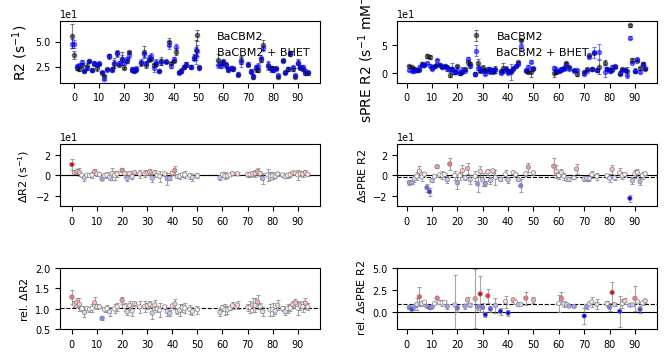

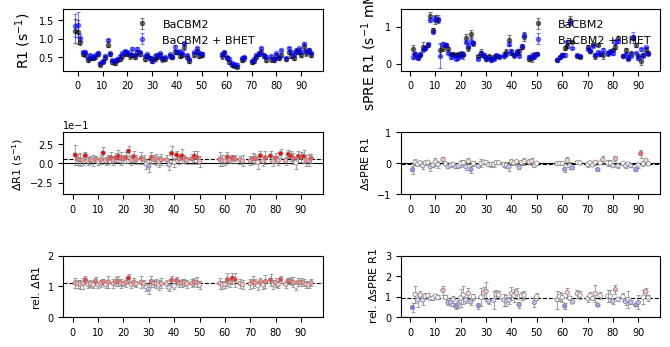

In [62]:
data = [R1_bhet_Ba, R2_bhet_Ba, PRE_R1_bhet_Ba, PRE_R2_bhet_Ba]
plot_title = 'BaCBM2 BHET'

textfile = "files/" + plot_title + ".txt"
with open(textfile, "w") as f:
    f.write("Before removing points \n")
deltaR1, deltaR2, deltaPRE_R1, deltaPRE_R2= calc_dR_dPRE(data, plot_title, textfile, print_details=True)

with open(textfile, "a") as f:
    f.write("\n")
    f.write("After removing points \n")

plt.rcParams.update({'font.size':6, "xtick.labelsize": 7,"ytick.labelsize": 7})
fig, axs = plt.subplots(3, 2, figsize =(7.7, 4), sharey = False)
fig.subplots_adjust(wspace=0.3, hspace=1)

plot_free_vs_bound(deltaR2, axs[0,0], plot_title, 'R2')
plot_change(deltaR2, axs[1,0], plot_title, 'R2', textfile)
plot_change(deltaR2, axs[2,0], plot_title, 'R2', textfile, rel = True)

plot_free_vs_bound(deltaPRE_R2, axs[0,1], plot_title, 'PRE_R2')
plot_change(deltaPRE_R2, axs[1,1], plot_title, 'PRE_R2', textfile)
plot_change(deltaPRE_R2, axs[2,1], plot_title, 'PRE_R2', textfile, rel = True)
plt.savefig('plots/PRE_bhet_r2.svg')


fig, axs = plt.subplots(3, 2, figsize =(7.7, 4), sharey = False)
fig.subplots_adjust(wspace=0.3, hspace=1)

plot_free_vs_bound(deltaR1, axs[0,0], plot_title, 'R1')
plot_change(deltaR1, axs[1,0], plot_title, 'R1', textfile)
plot_change(deltaR1, axs[2,0], plot_title, 'R1', textfile, rel = True)

plot_free_vs_bound(deltaPRE_R1, axs[0,1], plot_title, 'PRE_R1')
plot_change(deltaPRE_R1, axs[1,1], plot_title, 'PRE_R1', textfile)
plot_change(deltaPRE_R1, axs[2,1], plot_title, 'PRE_R1', textfile, rel = True)
plt.savefig('plots/PRE_bhet_r1.svg')

W9: 0.042, W44: 0.068, W63: 0.038
relative: W9: 1.137, W44: 1.135, W63: 1.144
W9: 2.637, W44: -0.477, W63: -1.063
relative: W9: 1.112, W44: 0.980, W63: 0.955
W9: -0.003, W44: -0.064, W63: 0.151
relative: W9: 0.996, W44: 0.862, W63: 1.127
W9: -8.273, W44: 3.714, W63: 1.653
relative: W9: 0.715, W44: 1.186, W63: 1.090
R2


R2, rel


PRE_R2


PRE_R2, rel


R1


R1, rel


PRE_R1


PRE_R1, rel


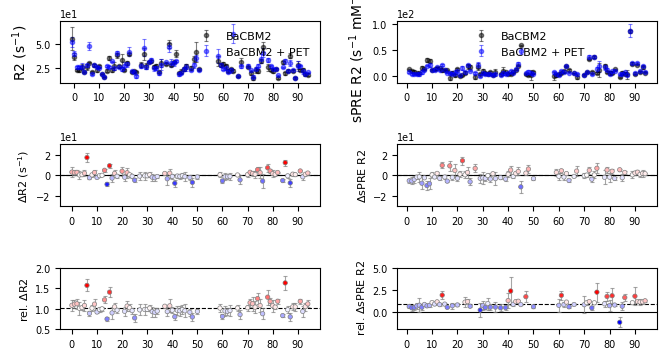

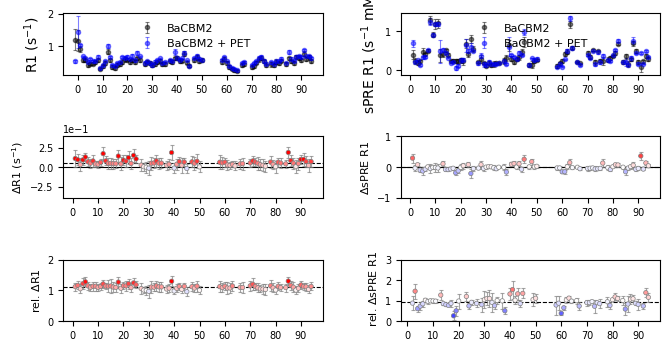

In [63]:
data = [R1_pet_Ba, R2_pet_Ba, PRE_R1_pet_Ba, PRE_R2_pet_Ba]
plot_title = 'BaCBM2 PET'

textfile = "files/" + plot_title + ".txt"
with open(textfile, "w") as f:
    f.write("Before removing points \n")
deltaR1, deltaR2, deltaPRE_R1, deltaPRE_R2= calc_dR_dPRE(data, plot_title, textfile, print_details=True)

with open(textfile, "a") as f:
    f.write("\n")
    f.write("After removing points \n")

plt.rcParams.update({'font.size':6, "xtick.labelsize": 7,"ytick.labelsize": 7})
fig, axs = plt.subplots(3, 2, figsize =(7.7, 4), sharey = False)
fig.subplots_adjust(wspace=0.3, hspace=1)

plot_free_vs_bound(deltaR2, axs[0,0], plot_title, 'R2')
plot_change(deltaR2, axs[1,0], plot_title, 'R2', textfile)
plot_change(deltaR2, axs[2,0], plot_title, 'R2', textfile, rel = True)

plot_free_vs_bound(deltaPRE_R2, axs[0,1], plot_title, 'PRE_R2')
plot_change(deltaPRE_R2, axs[1,1], plot_title, 'PRE_R2', textfile)
plot_change(deltaPRE_R2, axs[2,1], plot_title, 'PRE_R2', textfile, rel = True)

plt.savefig('plots/PRE_pet_r2.svg')

fig, axs = plt.subplots(3, 2, figsize =(7.7, 4), sharey = False)
fig.subplots_adjust(wspace=0.3, hspace=1)

plot_free_vs_bound(deltaR1, axs[0,0], plot_title, 'R1')
plot_change(deltaR1, axs[1,0], plot_title, 'R1', textfile)
plot_change(deltaR1, axs[2,0], plot_title, 'R1', textfile, rel = True)

plot_free_vs_bound(deltaPRE_R1, axs[0,1], plot_title, 'PRE_R1')
plot_change(deltaPRE_R1, axs[1,1], plot_title, 'PRE_R1', textfile)
plot_change(deltaPRE_R1, axs[2,1], plot_title, 'PRE_R1', textfile, rel = True)

plt.savefig('plots/PRE_pet_r1.svg')